# CMIP6 torchcrop runs — spatial differences

Where does simulated winter-wheat yield differ, between the runs and from today's climate? Changes
are per model first, then averaged. Hatching marks cells where fewer than 3 of 4 models share the sign
of the multi-model mean, so an unhatched cell means models agree on sign, not that the change is large.


**Reading these numbers**

* **Scope.** Torchcrop only, on calibrated parameters, for 4 models × 5 experiments, one run per
  model-experiment. Differences between experiments of one model include internal variability.
* **Cells.** The 59,304 cells every run simulated, weighted by cropland area. Each forcing has its own
  frame, and all 5,572 dropped cells lie outside the box the frames share.
* **Fixed crop system.** Cultivar, fertiliser and sowing (per-cell median of the MSWX SIMPLACE dates)
  do not change, so nothing here includes adaptation and sowing cannot respond to the forcing.
* **Wind** is an MSWX climatology in every run, so wind carries no scenario signal.
* **`hist-aer` holds CO₂ at 1850 (284 ppm)**; the other experiments follow their own CO₂. A contrast with
  `hist-aer` therefore mixes the climate effect with the CO₂ effect on the crop.
* **`yield_t_ha` excludes heat sterility.** `adjusted_yield_t_ha` = yield × (1 − heat stress). The
  calibration and evaluation use `yield_t_ha`, so it is the primary series here (see 04's sensitivity test).
* **No season 2015.** Historical runs end at harvest 2014, and SSP runs start with sowing in 2015.

## Findings

**Yield rises almost everywhere, but the gain comes mainly from the CO₂ parameter (notebook 05), and the pattern partly reflects the calibration.**

* **Future change, Europe vs 1985–2014:** +8.0 % [4.9, 10.7] in `ssp126` 2071–2100 and +28.7 % [22.9, 33.5] in `ssp370` 2071–2100, multi-model mean [model range]. Under `ssp370` the signal is robust on 86 % of cropland, and under `ssp126` on 58 %.
* **Losses are confined to the far south:** southern Spain and Portugal, Sicily, the southern Turkish coast and North Africa. Spain (+1 %) and Greece (+3 %) gain least under `ssp126`, and Denmark gains most (+13 %, and +37 % under `ssp370`).
* **Anchoring is good:** against the MSWX run over 2000–2014, the Europe bias is −7.4 % to +4.4 % and pattern r is 0.97–0.99.
* **Forcing:** over 1985–2014, `hist-aer` is about 1 t/ha below `historical`, but CO₂ is held at 1850 in that run, so this is not an aerosol effect. The clean climate contrast is `hist-GHG − historical` at −0.12 t/ha in Europe and −0.45 t/ha in Eastern Europe, from one run per model.

**Calibration artefacts (§9).** The straight-edged bands in the east are calibration-region boundaries. North–south jumps in baseline yield are 13× larger across a boundary (0.90 vs 0.07 t/ha). Only 43 % of cropland has a CyBench unit, with none in Eastern Europe or West-Central Asia, and region 20 (3.4 % of cropland) runs on the fallback crop. Fine spatial detail outside the EU-23 is not reliable, so prefer the EU-23 row: +9.1 % and +24.7 %.

## 0. Setup

In [1]:
import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

sys.path.insert(0, str(Path.cwd()))
import scenarios as sc
from cropmodelling4eu.evaluation.plots import save
from cropmodelling4eu.evaluation.style import SEQUENTIAL_CMAP, DIVERGING_CMAP, use_style

logging.basicConfig(level=logging.WARNING, force=True)
PALETTE = use_style("light")
plt.rcParams["figure.dpi"] = 90
FIGURES, TABLES = sc.table_dir("spatial")
cells = sc.load_cells()
y = sc.cube("yield_t_ha")
EXP_COLOURS = {"historical": PALETTE["primary"], "hist-GHG": PALETTE["series_4"], "hist-aer": PALETTE["series_3"],
               "ssp126": PALETTE["series_1"], "ssp370": PALETTE["series_2"]}
MODEL_COLOURS = dict(zip(sc.MODELS, (PALETTE[f"series_{i}"] for i in (1, 2, 3, 5))))
SPAN = lambda s: f"{s[0]}–{s[1]}"

print(f"{cells.n} cells; outputs in {FIGURES.parent}")

59304 cells; outputs in /data01/FDS/muduchuru/Data/SIMPLACE/cropmodelling4eu/runs/winter_wheat/calibrated/cmip6/analysis/spatial


## 1. Which cells are compared

The table lists, per run, the cells with no yield in any year. The map shows what the common mask removes.

experiment,historical,hist-GHG,hist-aer,ssp126,ssp370
model,,,,,
ACCESS-ESM1-5,5572,5572,5572,5572,5572
IPSL-CM6A-LR,4160,4160,4160,4160,4160
MIROC6,4218,4218,4218,4218,4218
MRI-ESM2-0,4309,4309,4309,4309,4309


Run cells 64,876; common 59,304; dropped 5,572, of which inside the shared frame box: 0
MSWX production cells not in any CMIP6 run: 3,809
Cropland in the common set: 987,796 km²; in CyBench countries: 426,651 km²


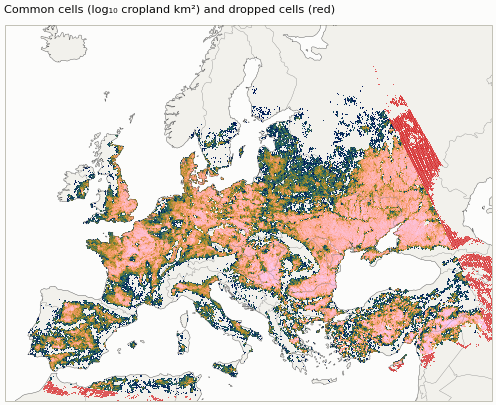

In [2]:
inv = sc.run_inventory()
inv["no yield"] = inv["null"].map(len)
display(inv.pivot(index="model", columns="experiment", values="no yield")[list(sc.EXPERIMENTS)])

held = set.intersection(*inv["cells"])
lost = pd.Index(sorted(set.union(*inv["null"])))
index = lost.to_numpy() - 1
lost_frame = pd.DataFrame({"lat": sc.MAX_LAT - sc.RES / 2 - (index // sc.N_LON) * sc.RES,
                           "lon": sc.MIN_LON + sc.RES / 2 + (index % sc.N_LON) * sc.RES}, index=lost)
box = sc.COMMON_BOX
inside = lost_frame["lat"].between(*box["lat"]) & lost_frame["lon"].between(*box["lon"])
mswx_ids = set(sc.mswx_cube().cell.values) | set(pd.read_parquet(sc.MSWX_RUN / "torchcrop" / "torchcrop_europe.parquet", columns=["SimplaceID"])["SimplaceID"].unique())
print(f"Run cells {len(held):,}; common {cells.n:,}; dropped {len(lost):,}, of which inside the shared frame box: {int(inside.sum())}")
print(f"MSWX production cells not in any CMIP6 run: {len(mswx_ids - held):,}")
print(f"Cropland in the common set: {cells.weight.sum():,.0f} km²; in CyBench countries: {cells.frame.loc[cells.frame.adm_country.notna(), 'cropland_km2'].sum():,.0f} km²")

fig, ax = sc.map_axes(1, 1, 5.5, 5.0)
ax = ax[0, 0]
sc.draw_map(ax, np.log10(cells.weight + 0.1), cmap=SEQUENTIAL_CMAP, title="Common cells (log₁₀ cropland km²) and dropped cells (red)")
import cartopy.crs as ccrs
ax.scatter(lost_frame["lon"], lost_frame["lat"], s=0.4, c="tab:red", linewidths=0, transform=ccrs.PlateCarree(), zorder=4)
save(fig, "mask", FIGURES)
plt.show()

## 2. Are the runs anchored to the MSWX run?

The forcing is bias-corrected to MSWX, so `historical` should reproduce the MSWX run's **mean state** over the 15 shared seasons (2000–2014). A free-running model has its own weather sequence, so individual years and interannual correlation are not comparable.

,MSWX (t/ha),historical (t/ha),bias (t/ha),bias (%),RMSE (t/ha),pattern r
model,,,,,,
ACCESS-ESM1-5,4.036,3.737,-0.299,-7.410,0.554,0.973
IPSL-CM6A-LR,4.036,3.986,-0.050,-1.233,0.338,0.986
MIROC6,4.036,4.181,0.146,3.606,0.439,0.979
MRI-ESM2-0,4.036,4.213,0.177,4.389,0.382,0.986


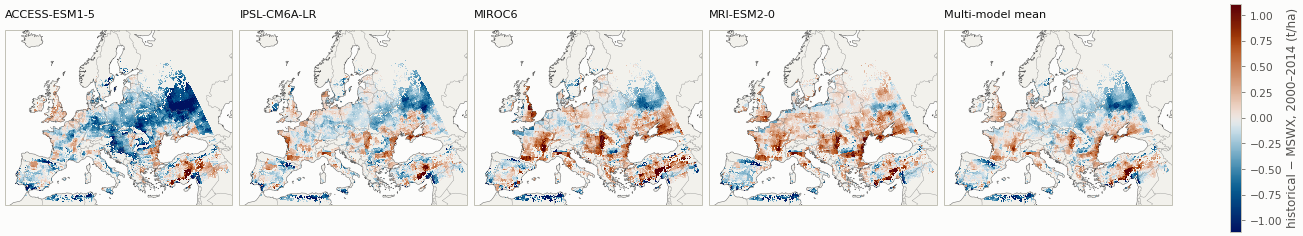

In [3]:
SHARED = (2000, 2014)
mswx = sc.clim(sc.mswx_cube(), SHARED)
diff = sc.clim(y.sel(experiment="historical"), SHARED) - mswx
rel = 100.0 * diff / mswx.where(mswx > 0)
weights = cells.weight / cells.weight.sum()
rows = []
for m in sc.MODELS:
    sim = sc.clim(y.sel(experiment="historical", model=m), SHARED).values
    ok = np.isfinite(sim) & np.isfinite(mswx.values)
    mx, my = np.average(mswx.values[ok], weights=weights[ok]), np.average(sim[ok], weights=weights[ok])
    cov = np.average((mswx.values[ok] - mx) * (sim[ok] - my), weights=weights[ok])
    r = cov / np.sqrt(np.average((mswx.values[ok] - mx) ** 2, weights=weights[ok]) * np.average((sim[ok] - my) ** 2, weights=weights[ok]))
    rows.append({"model": m, "MSWX (t/ha)": mx, "historical (t/ha)": my, "bias (t/ha)": my - mx, "bias (%)": 100 * (my / mx - 1),
                 "RMSE (t/ha)": np.sqrt(np.average((sim[ok] - mswx.values[ok]) ** 2, weights=weights[ok])), "pattern r": r})
anchor = pd.DataFrame(rows).set_index("model")
anchor.to_csv(TABLES / "historical_vs_mswx.csv")
display(anchor.round(3))

fig, axes = sc.map_axes(1, 5, 2.9, 3.2)
scale = sc.diverging(diff)
for ax, m in zip(axes[0], sc.MODELS):
    mesh = sc.draw_map(ax, diff.sel(model=m).values, title=m, **scale)
mesh = sc.draw_map(axes[0, 4], diff.mean("model").values, title="Multi-model mean", **scale)
fig.colorbar(mesh, ax=axes[0], shrink=0.7, label=f"historical − MSWX, {SPAN(SHARED)} (t/ha)")
save(fig, "historical_minus_mswx", FIGURES)
plt.show()

## 3. Baseline climate of the yield, 1985–2014

Multi-model mean, the spread between models, and each model's departure from that mean.

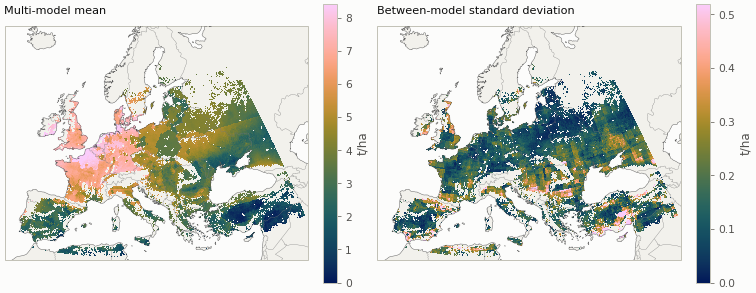

model,ACCESS-ESM1-5,IPSL-CM6A-LR,MIROC6,MRI-ESM2-0
region,,,,
Europe (all cells),3.82,4.00,4.02,4.11
EU-23 (CyBench countries),5.08,5.25,5.34,5.37
Northern Europe,6.93,7.02,7.26,7.03
Western & Central Europe,4.39,4.60,4.62,4.72
Eastern Europe,2.76,2.98,3.02,3.11
Mediterranean,2.39,2.47,2.44,2.60


In [4]:
base = sc.clim(y.sel(experiment="historical"), sc.BASELINE)
fig, axes = sc.map_axes(1, 2, 4.2, 4.0)
fig.colorbar(sc.draw_map(axes[0, 0], base.mean("model").values, cmap=SEQUENTIAL_CMAP, vmin=0, vmax=float(base.mean("model").quantile(0.99)), title="Multi-model mean"), ax=axes[0, 0], shrink=0.7, label="t/ha")
fig.colorbar(sc.draw_map(axes[0, 1], base.std("model").values, cmap=SEQUENTIAL_CMAP, vmin=0, vmax=float(base.std("model").quantile(0.99)), title="Between-model standard deviation"), ax=axes[0, 1], shrink=0.7, label="t/ha")
save(fig, "baseline_climatology", FIGURES)
plt.show()
display(sc.regional_mean(base).to_pandas().T.rename(index=sc.REGION_NAMES).round(2))

## 4. Future change against 1985–2014

Change relative to each model's own baseline. Hatching marks cells where models disagree on the sign. Regional % values are the ratio of regional means, not the mean of per-cell %, which low-yield cells would dominate.

Cells with a baseline below 1.0 t/ha in any model are blank in % maps (8.0 % of cropland)


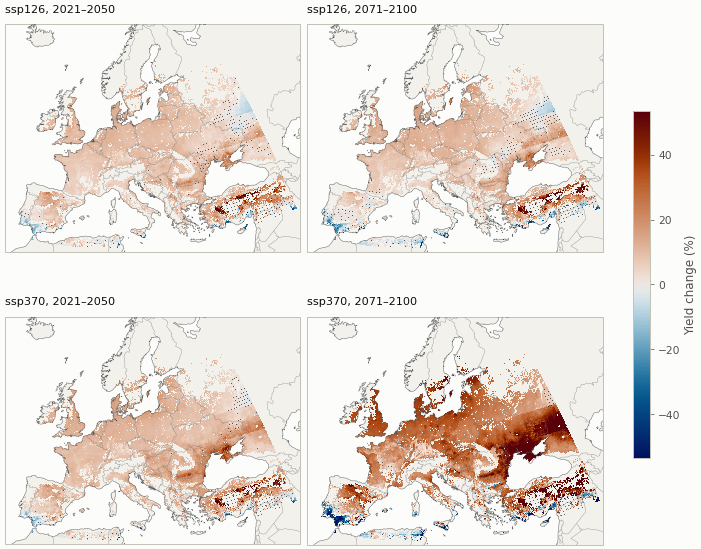

,ssp126 2021–2050: %,ssp126 2021–2050: t/ha,ssp126 2071–2100: %,ssp126 2071–2100: t/ha,ssp370 2021–2050: %,ssp370 2021–2050: t/ha,ssp370 2071–2100: %,ssp370 2071–2100: t/ha
Europe (all cells),"+7.69 [+5.47, +10.90]","+0.31 [+0.22, +0.42]","+8.04 [+4.94, +10.69]","+0.32 [+0.19, +0.44]","+11.08 [+6.42, +14.81]","+0.44 [+0.25, +0.60]","+28.67 [+22.89, +33.52]","+1.15 [+0.92, +1.35]"
EU-23 (CyBench countries),"+8.84 [+7.23, +11.46]","+0.46 [+0.39, +0.58]","+9.08 [+7.57, +10.76]","+0.48 [+0.40, +0.58]","+11.27 [+9.48, +12.32]","+0.59 [+0.48, +0.66]","+24.71 [+20.31, +29.31]","+1.30 [+1.07, +1.57]"
Northern Europe,"+10.81 [+8.72, +12.24]","+0.76 [+0.60, +0.86]","+12.27 [+10.64, +14.10]","+0.87 [+0.75, +0.99]","+13.30 [+10.63, +15.34]","+0.94 [+0.74, +1.08]","+35.56 [+30.45, +40.10]","+2.51 [+2.14, +2.82]"
Western & Central Europe,"+7.52 [+5.56, +11.07]","+0.34 [+0.26, +0.49]","+7.97 [+5.34, +10.13]","+0.37 [+0.23, +0.48]","+10.69 [+5.98, +14.26]","+0.49 [+0.26, +0.66]","+28.01 [+22.33, +34.39]","+1.29 [+1.01, +1.59]"
Eastern Europe,"+1.20 [-2.74, +6.80]","+0.03 [-0.08, +0.19]","+2.09 [-5.97, +9.34]","+0.07 [-0.16, +0.29]","+7.41 [-7.78, +16.34]","+0.23 [-0.21, +0.51]","+32.82 [+23.68, +41.78]","+0.98 [+0.70, +1.30]"
Mediterranean,"+11.87 [+8.16, +15.75]","+0.29 [+0.20, +0.38]","+10.87 [+6.44, +13.10]","+0.27 [+0.15, +0.34]","+15.61 [+13.08, +19.25]","+0.38 [+0.33, +0.47]","+27.48 [+24.66, +29.97]","+0.68 [+0.61, +0.72]"


In [5]:
SCENARIOS = [(e, s) for e in sc.FUTURE for s in (sc.NEAR, sc.FAR)]
pct = {(e, s): sc.relative_change(y, e, s) for e, s in SCENARIOS}
blank = 100 * cells.weight[(sc.clim(y.sel(experiment="historical"), sc.BASELINE) < sc.MIN_BASE_YIELD).any("model").values].sum() / cells.weight.sum()
print(f"Cells with a baseline below {sc.MIN_BASE_YIELD} t/ha in any model are blank in % maps ({blank:.1f} % of cropland)")
absolute = {(e, s): sc.absolute_change(y, e, s) for e, s in SCENARIOS}
scale = sc.diverging(xr.concat([v.mean("model") for v in pct.values()], "k"))
fig, axes = sc.map_axes(2, 2, 3.9, 3.0)
for ax, (key, delta) in zip(axes.ravel(), pct.items()):
    mesh = sc.draw_map(ax, delta.mean("model").values, title=f"{key[0]}, {SPAN(key[1])}", hatch=~sc.agreement(delta).values, **scale)
fig.colorbar(mesh, ax=axes, shrink=0.6, label="Yield change (%)")
save(fig, "future_change_pct", FIGURES)
plt.show()
table = sc.regional_table({f"{e} {SPAN(s)}: {u}": (sc.regional_relative_change(y, e, s) if u == "%" else absolute[(e, s)]) for e, s in SCENARIOS for u in ("%", "t/ha")}, 2)
table.to_csv(TABLES / "future_change_regions.csv")
display(table.T)

The same far-future change, model by model:

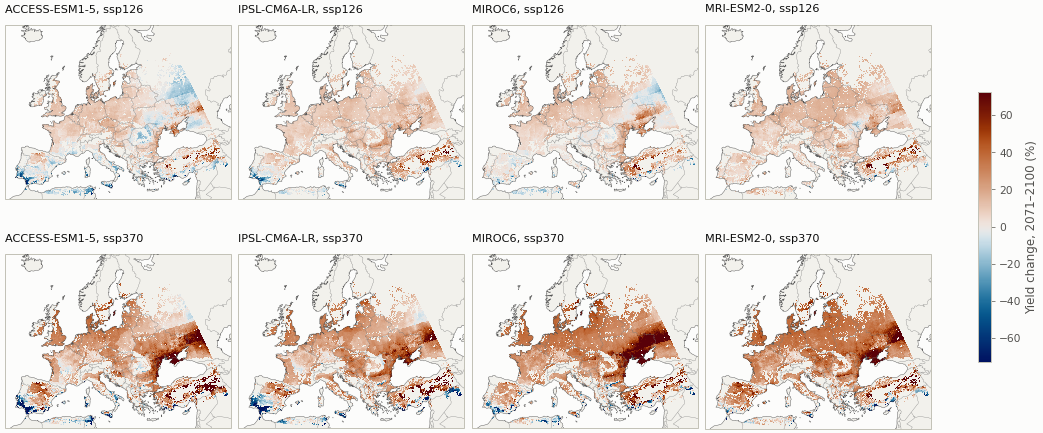

In [6]:
fig, axes = sc.map_axes(2, 4, 2.9, 2.3)
scale = sc.diverging(xr.concat([pct[(e, sc.FAR)] for e in sc.FUTURE], "k"))
for r, e in enumerate(sc.FUTURE):
    for c, m in enumerate(sc.MODELS):
        mesh = sc.draw_map(axes[r, c], pct[(e, sc.FAR)].sel(model=m).values, title=f"{m}, {e}", **scale)
fig.colorbar(mesh, ax=axes, shrink=0.6, label=f"Yield change, {SPAN(sc.FAR)} (%)")
save(fig, "future_change_models", FIGURES)
plt.show()

## 5. Scenario difference: ssp370 − ssp126

The same models and periods, with different emissions. CO₂ reaches 867 ppm against 446 ppm in 2100, so a positive value can be CO₂ fertilisation winning over stronger warming. Notebook 05 separates the two.

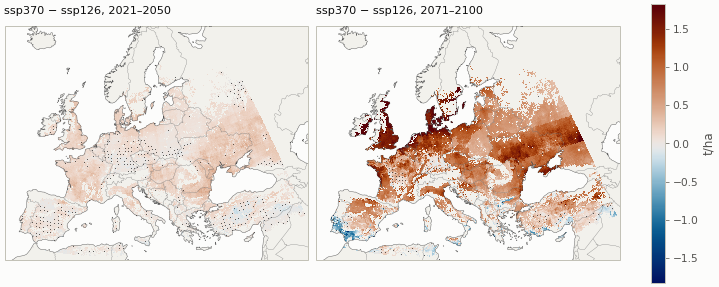

,2021–2050,2071–2100
Europe (all cells),"+0.14 [-0.17, +0.33]","+0.82 [+0.52, +1.08]"
EU-23 (CyBench countries),"+0.13 [-0.10, +0.27]","+0.83 [+0.55, +1.10]"
Northern Europe,"+0.18 [+0.12, +0.23]","+1.65 [+1.39, +1.83]"
Western & Central Europe,"+0.15 [-0.22, +0.38]","+0.92 [+0.58, +1.28]"
Eastern Europe,"+0.20 [-0.40, +0.55]","+0.91 [+0.47, +1.20]"
Mediterranean,"+0.09 [+0.03, +0.15]","+0.41 [+0.28, +0.56]"


In [7]:
gap = {s: clim_gap for s, clim_gap in ((s, sc.clim(y.sel(experiment="ssp370"), s) - sc.clim(y.sel(experiment="ssp126"), s)) for s in (sc.NEAR, sc.FAR))}
scale = sc.diverging(gap[sc.FAR].mean("model"))
fig, axes = sc.map_axes(1, 2, 4.0, 4.0)
for ax, (s, delta) in zip(axes[0], gap.items()):
    mesh = sc.draw_map(ax, delta.mean("model").values, title=f"ssp370 − ssp126, {SPAN(s)}", hatch=~sc.agreement(delta).values, **scale)
fig.colorbar(mesh, ax=axes, shrink=0.7, label="t/ha")
save(fig, "ssp370_minus_ssp126", FIGURES)
plt.show()
display(sc.regional_table({SPAN(s): d for s, d in gap.items()}, 2).T)

## 6. Forcing contrasts in the historical period

| Contrast | What differs | CO₂ on the crop |
|---|---|---|
| `hist-GHG − historical`, 1985–2014 | No aerosol or natural forcing in `hist-GHG` | Same |
| `historical − hist-aer`, 1985–2014 | GHG climate, natural forcing and CO₂ | **Differs by ~85 ppm on average** |
| Change 1985–2014 vs 1951–1980 within each experiment | The forcing's change over time | Rises except in `hist-aer` |

Only the first row isolates a climate effect. The residual `Δhistorical − (Δhist-GHG + Δhist-aer)` is what a two-forcing sum leaves out: natural forcing, interaction and internal variability.

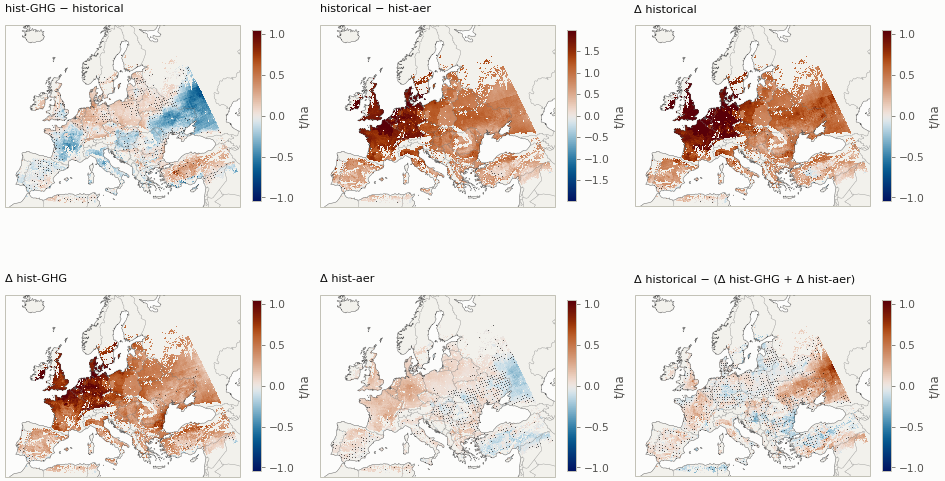

,hist-GHG − historical,historical − hist-aer,Δ historical,Δ hist-GHG,Δ hist-aer,Δ historical − (Δ hist-GHG + Δ hist-aer)
Europe (all cells),"-0.12 [-0.17, -0.08]","+0.97 [+0.82, +1.17]","+0.58 [+0.45, +0.68]","+0.44 [+0.37, +0.53]","+0.01 [-0.08, +0.08]","+0.12 [+0.01, +0.23]"
EU-23 (CyBench countries),"-0.02 [-0.12, +0.07]","+1.23 [+1.05, +1.43]","+0.71 [+0.60, +0.84]","+0.61 [+0.57, +0.63]","+0.09 [+0.06, +0.14]","+0.01 [-0.08, +0.14]"
Northern Europe,"+0.05 [-0.03, +0.15]","+1.76 [+1.68, +1.83]","+1.05 [+0.98, +1.10]","+0.87 [+0.80, +0.92]","+0.11 [+0.01, +0.23]","+0.07 [+0.01, +0.17]"
Western & Central Europe,"-0.13 [-0.16, -0.09]","+1.11 [+0.90, +1.35]","+0.65 [+0.50, +0.78]","+0.50 [+0.41, +0.57]","+0.05 [-0.03, +0.13]","+0.10 [-0.01, +0.22]"
Eastern Europe,"-0.45 [-0.61, -0.34]","+0.81 [+0.72, +0.92]","+0.57 [+0.33, +0.71]","+0.29 [+0.19, +0.53]","-0.15 [-0.42, +0.03]","+0.43 [+0.05, +0.86]"
Mediterranean,"+0.06 [-0.01, +0.14]","+0.56 [+0.38, +0.77]","+0.30 [+0.23, +0.37]","+0.31 [+0.26, +0.38]","+0.00 [-0.06, +0.08]","-0.02 [-0.15, +0.06]"


In [8]:
contrasts = {
    "hist-GHG − historical": sc.clim(y.sel(experiment="hist-GHG"), sc.BASELINE) - sc.clim(y.sel(experiment="historical"), sc.BASELINE),
    "historical − hist-aer": sc.clim(y.sel(experiment="historical"), sc.BASELINE) - sc.clim(y.sel(experiment="hist-aer"), sc.BASELINE),
}
within = {e: sc.clim(y.sel(experiment=e), sc.BASELINE) - sc.clim(y.sel(experiment=e), sc.EARLY) for e in sc.HISTORICAL}
contrasts |= {f"Δ {e}": v for e, v in within.items()}
contrasts["Δ historical − (Δ hist-GHG + Δ hist-aer)"] = within["historical"] - within["hist-GHG"] - within["hist-aer"]
fig, axes = sc.map_axes(2, 3, 3.5, 2.75)
limit = float(np.nanquantile(np.abs(xr.concat([v.mean("model") for k, v in contrasts.items() if k != "historical − hist-aer"], "k").values), 0.98))
for ax, (name, delta) in zip(axes.ravel(), contrasts.items()):
    scale = sc.diverging(delta.mean("model")) if name == "historical − hist-aer" else {"cmap": DIVERGING_CMAP, "vmin": -limit, "vmax": limit}
    mesh = sc.draw_map(ax, delta.mean("model").values, title=name, hatch=~sc.agreement(delta).values, **scale)
    fig.colorbar(mesh, ax=ax, shrink=0.65, label="t/ha")
save(fig, "forcing_contrasts", FIGURES)
plt.show()
table = sc.regional_table(contrasts, 2)
table.to_csv(TABLES / "forcing_contrasts_regions.csv")
display(table.T)

## 7. Change per country

CyBench countries with at least 2,000 km² of cropland; bars show the multi-model mean and dots each model.

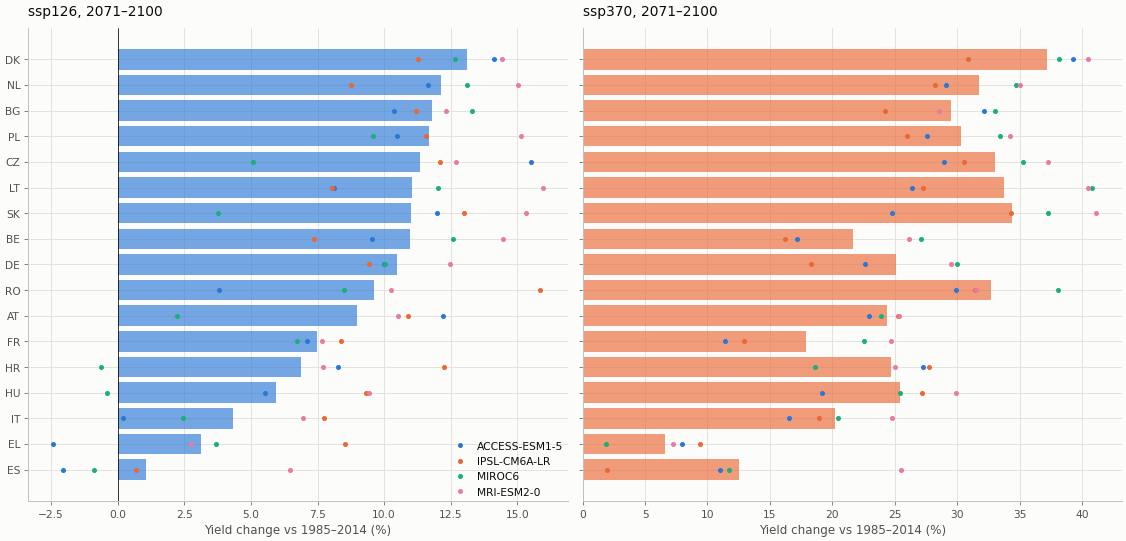

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 6.0), sharey=True, layout="constrained")
store = {}
for ax, e in zip(axes, sc.FUTURE):
    by_country = sc.regional_relative_change(y, e, sc.FAR, aggregate=sc.country_series)
    order = by_country.mean("model").sortby(by_country.mean("model"))
    store[e] = order.to_series()
    ax.barh(order.country.values, order.values, color=EXP_COLOURS[e], alpha=0.65)
    for m in sc.MODELS:
        ax.plot(by_country.sel(model=m, country=order.country).values, order.country.values, "o", ms=3, color=MODEL_COLOURS[m], label=m)
    ax.axvline(0, color="k", lw=0.6)
    ax.set(title=f"{e}, {SPAN(sc.FAR)}", xlabel="Yield change vs 1985–2014 (%)")
axes[0].legend(frameon=False)
save(fig, "country_change", FIGURES)
plt.show()
pd.DataFrame(store).to_csv(TABLES / "country_change_far.csv")

## 8. How robust is the spatial signal?

The share of cropland where the change is robust: at least 3 of 4 models agree on the sign, and the multi-model mean exceeds both 5 % and the between-model standard deviation.

In [10]:
rows = []
for key, delta in pct.items():
    mean, spread = delta.mean("model"), delta.std("model")
    robust = sc.agreement(delta) & (np.abs(mean) > 5) & (np.abs(mean) > spread)
    w = cells.weight / cells.weight.sum()
    rows.append({"scenario": key[0], "period": SPAN(key[1]),
                 "cropland gaining, robust (%)": 100 * float((w * (robust & (mean > 0))).sum()),
                 "cropland losing, robust (%)": 100 * float((w * (robust & (mean < 0))).sum()),
                 "cropland not robust (%)": 100 * float((w * ~robust).sum()),
                 "median between-model SD (%)": float(spread.median())})
robustness = pd.DataFrame(rows)
robustness.to_csv(TABLES / "robustness.csv", index=False)
display(robustness.round(1))

,scenario,period,"cropland gaining, robust (%)","cropland losing, robust (%)",cropland not robust (%),median between-model SD (%)
0,ssp126,2021–2050,52.4,2.4,45.3,4.1
1,ssp126,2071–2100,57.0,1.4,41.7,4.4
2,ssp370,2021–2050,74.4,0.4,25.2,4.8
3,ssp370,2071–2100,84.8,0.8,14.3,6.9


## 9. Calibration regions show in the change

The maps carry straight-edged bands in the east, in the same place in every model, so they do not come from a GCM's grid. Their edges are the boundaries of the calibration regions (28 clusters): each region has its own crop parameters, so neighbouring cells with almost the same weather can respond differently.

This section measures that effect, and how much cropland relies on parameters fitted to no local yield record. A CyBench cell belongs to a region fitted against its own unit's reported yields. A cell without a unit was only assigned to a region, so its parameters are extrapolated.

North–south neighbours: 3,885 pairs across a region boundary, 48,965 within


,same region,across a boundary
baseline yield (t/ha),0.070,0.90
ssp370 far change (t/ha),0.049,0.33


Cropland with a CyBench unit: 43.2 %


,cropland_km2,with a CyBench unit,share (%)
ar6,,,
EEU,118038.0,NaN,0.0
MED,192248.0,94314.0,49.0
NEU,45881.0,21553.0,47.0
WCA,42413.0,NaN,0.0
WCE,589217.0,310785.0,53.0


Regions with no calibrated crop file (run on the fallback crop): [20]; 33,894 km² of cropland (3.4 %)


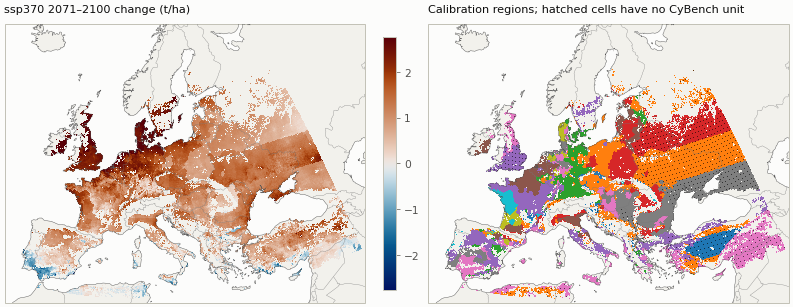

In [11]:
frame = cells.frame
far = sc.absolute_change(y, "ssp370", sc.FAR).mean("model").to_series()
base = sc.clim(y.sel(experiment="historical"), sc.BASELINE).mean("model").to_series()
south = frame.index + sc.N_LON
has = south.isin(frame.index)
north_ids, south_ids = frame.index[has], south[has]
across = frame.loc[north_ids, "region_id"].to_numpy() != frame.loc[south_ids, "region_id"].to_numpy()
def jump(values, mask):
    return float(np.nanmedian(np.abs(values.loc[north_ids].to_numpy() - values.loc[south_ids].to_numpy())[mask]))
print(f"North–south neighbours: {int(across.sum()):,} pairs across a region boundary, {int((~across).sum()):,} within")
display(pd.DataFrame({"same region": {"baseline yield (t/ha)": jump(base, ~across), "ssp370 far change (t/ha)": jump(far, ~across)},
                      "across a boundary": {"baseline yield (t/ha)": jump(base, across), "ssp370 far change (t/ha)": jump(far, across)}}).round(3))
coverage = (frame.assign(observed=frame["adm_id"].notna()).groupby("ar6")[["cropland_km2"]].sum().join(
    frame[frame["adm_id"].notna()].groupby("ar6")["cropland_km2"].sum().rename("with a CyBench unit")))
coverage["share (%)"] = 100 * coverage["with a CyBench unit"].fillna(0) / coverage["cropland_km2"]
print(f"Cropland with a CyBench unit: {100 * frame.loc[frame.adm_id.notna(), 'cropland_km2'].sum() / frame['cropland_km2'].sum():.1f} %")
coverage.to_csv(TABLES / "calibration_coverage.csv")
display(coverage.round(0))
calibrated = {int(p.stem.rsplit("_", 1)[1]) for p in (sc.CALIBRATION / "yield" / "crops").glob("crop_region_*.yaml")}
fallback = frame[~frame["region_id"].isin(calibrated)]
print(f"Regions with no calibrated crop file (run on the fallback crop): {sorted(fallback['region_id'].unique().tolist())}; {fallback['cropland_km2'].sum():,.0f} km² of cropland ({100 * fallback['cropland_km2'].sum() / frame['cropland_km2'].sum():.1f} %)")
codes = frame["region_id"].to_numpy()
fig, axes = sc.map_axes(1, 2, 4.4, 3.6)
fig.colorbar(sc.draw_map(axes[0, 0], far.to_numpy(), title="ssp370 2071–2100 change (t/ha)", **sc.diverging(far.to_numpy())), ax=axes[0, 0], shrink=0.7)
sc.draw_map(axes[0, 1], codes % 10, cmap="tab10", vmin=0, vmax=9, title="Calibration regions; hatched cells have no CyBench unit", hatch=frame["adm_id"].isna().to_numpy())
save(fig, "calibration_regions", FIGURES)
plt.show()